In [2]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

In [3]:
runs=['oper_01','oper_02', 'oper_03', 'oper_04']

In [4]:
tsr = xr.open_mfdataset([f'/jetfs/scratch/psplechtna/thesisdata/oper/2024/{run}_tsr.nc' for run in runs])

In [5]:
# calculate errors
abs_err = np.abs(tsr.calc.values-tsr.diag.values).mean()
rmse = np.sqrt(1/len(tsr.release_date) * np.sum((tsr.calc.values-tsr.diag.values)**2))

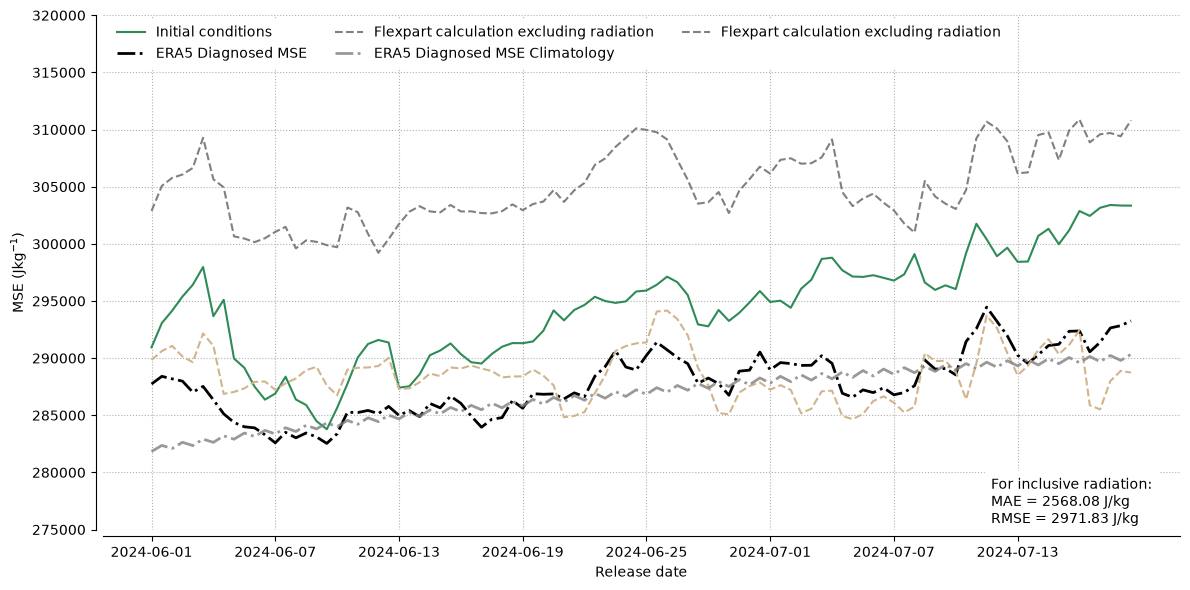

In [6]:
fig, ax = plt.subplots(1, 1, figsize=(12,6))

xes = tsr.release_date

l_init, = ax.plot(xes, tsr.init, color='seagreen', label='Initial conditions')
l_diagnosed, = ax.plot(xes, tsr.diag, '-.k', linewidth=2, label='ERA5 Diagnosed MSE')
l_incl, = ax.plot(xes, tsr.calc, color='tan', linestyle='--', label='Flexpart calculation including radiation')
l_incl, = ax.plot(xes, tsr.calc_wo, color='grey', linestyle='--', label='Flexpart calculation excluding radiation')
l_diag_clim, = ax.plot(xes, tsr.diag - tsr.diag_anomaly, '-.', color='grey', alpha=0.8, linewidth=2, label='ERA5 Diagnosed MSE Climatology')


ax.set_ylabel('MSE (Jkg$^{-1}$)')
ax.set_xticks(xes[::12])
ax.set_xlabel('Release date')
ax.set_ylim(275000, 320000)

# make prettier
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
spine_offset=5
ax.spines.left.set_position(('outward', spine_offset))
ax.spines.bottom.set_position(('outward', spine_offset))
ax.grid(linestyle=':')


#fig.text(
#    x=0.75, y=0.82,
#    s=(f'Pearson Correlation:\n'
#       f'r = {np.corrcoef(tsr.calc, tsr.diag)[0,1]:.2f} for incl radiation\n'
#       f'r = {np.corrcoef(tsr.init, tsr.diag)[0,1]:.2f} for initial conditions only\n'
#       f'r = {np.corrcoef(tsr.calc_wo, tsr.diag)[0,1]:.2f} for excl radiation'),
#    backgroundcolor='white',
#)

fig.text(x=0.83, y=0.12, s=f'For inclusive radiation:\nMAE = {abs_err:.2f} J/kg\nRMSE = {rmse:.2f} J/kg',
        backgroundcolor='white')


fig.legend(handles=[l_init, l_diagnosed, l_incl, l_diag_clim, l_incl], loc='upper center', bbox_to_anchor=(0.47, 0.97), ncol=3,
           frameon=True, framealpha=1, edgecolor='white', fontsize=10)
fig.tight_layout()


#fig.savefig('tsr_rad.png')

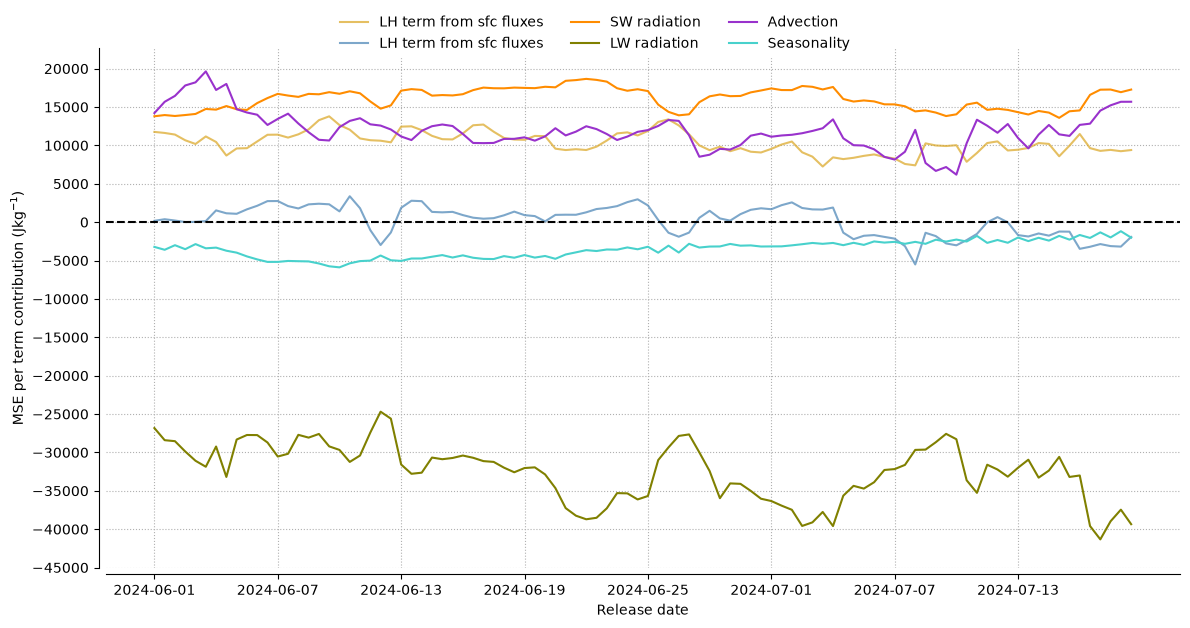

In [7]:
# single terms
fig, ax = plt.subplots(1, 1, figsize=(12,6))

int_f_lh, = ax.plot(xes, tsr.flux_lh, color='goldenrod', alpha=0.7, 
                    linestyle='-', label='LH term from sfc fluxes')
int_f_sh, = ax.plot(xes, tsr.flux_sh, color='steelblue', alpha=0.7, 
                    linestyle='-', label='LH term from sfc fluxes')

int_s_rad, = ax.plot(xes, tsr.sw_rad, color='darkorange', label='SW radiation')
int_l_rad, = ax.plot(xes, tsr.lw_rad, color='olive', label='LW radiation')
int_l_adv, = ax.plot(xes, tsr.advection, color='darkorchid', label='Advection')
int_l_seas, = ax.plot(xes, tsr.seasonality, color='mediumturquoise', label='Seasonality')


ax.set_ylabel('MSE per term contribution (Jkg$^{-1}$)')
ax.set_xticks(xes[::12])
ax.set_xlabel('Release date')

#ax.set_ylim(-46000, 22000)
ax.set_yticks(np.arange(-45000, 21000, 5000))

ax.axhline(0, linestyle='--', color='k')

# make prettier
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
spine_offset=5
ax.spines.left.set_position(('outward', spine_offset))
ax.spines.bottom.set_position(('outward', spine_offset))
ax.grid(linestyle=':')

fig.legend(handles=[int_f_lh, int_f_sh, int_s_rad, int_l_rad, int_l_adv, int_l_seas], loc='upper center', bbox_to_anchor=(0.5, 1.05), ncol=3,
           frameon=True, framealpha=1, edgecolor='white', fontsize=10)
fig.tight_layout()
#fig.savefig('allterms.png')